In [8]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud


In [9]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print(os.listdir(path))

df = pd.read_csv(os.path.join(path, "creditcard.csv"))
df.head()

['creditcard.csv']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [10]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:", df.isnull().sum().sum())
print("\nClass counts:")
print(df["Class"].value_counts())
print("\nFraud percentage:")
print(df["Class"].value_counts(normalize=True) * 100)

Shape: (284807, 31)

Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Missing values: 0

Class counts:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud percentage:
Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


In [11]:
df = df.sort_values("Time").reset_index(drop=True)

n = len(df)
train_end = int(0.6 * n)
val_end = int(0.8 * n)

# Move boundaries to the next distinct timestamp
while train_end < n and df.loc[train_end - 1, "Time"] == df.loc[train_end, "Time"]:
    train_end += 1

while val_end < n and df.loc[val_end - 1, "Time"] == df.loc[val_end, "Time"]:
    val_end += 1

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(name, len(data), data["Class"].sum(),
          round(data["Class"].mean() * 100, 4), "%")

Train 170888 360 0.2107 %
Validation 56957 57 0.1001 %
Test 56962 75 0.1317 %


In [12]:
print("Train → Validation:")
print(train_df["Time"].max(), val_df["Time"].min())

print("Validation → Test:")
print(val_df["Time"].max(), test_df["Time"].min())

Train → Validation:
120396.0 120397.0
Validation → Test:
145247.0 145248.0


In [13]:
X_train = train_df.drop(columns="Class")
y_train = train_df["Class"]

X_val = val_df.drop(columns="Class")
y_val = val_df["Class"]

X_test = test_df.drop(columns="Class")
y_test = test_df["Class"]

print(X_train.shape, X_val.shape, X_test.shape)

(170888, 30) (56957, 30) (56962, 30)


In [14]:
from google.colab import drive
import os

# Connect Google Drive
drive.mount("/content/drive")

# Create project folder
folder = "/content/drive/MyDrive/STOR565_Project"
os.makedirs(folder, exist_ok=True)

# Save datasets
train_df.to_csv(f"{folder}/train.csv", index=False)
val_df.to_csv(f"{folder}/validation.csv", index=False)
test_df.to_csv(f"{folder}/test.csv", index=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


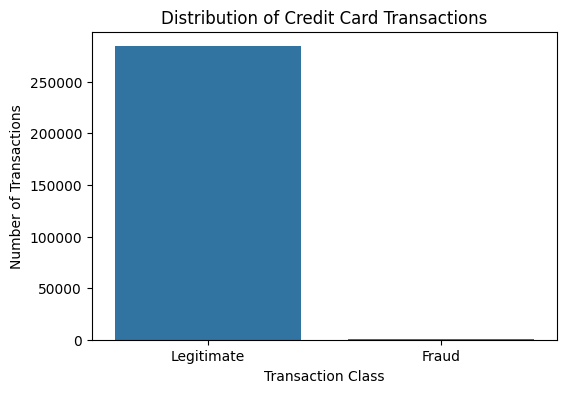

In [15]:
counts = df["Class"].value_counts().sort_index()

plt.figure(figsize=(6, 4))
sns.barplot(
    x=["Legitimate", "Fraud"],
    y=counts.values
)

plt.title("Distribution of Credit Card Transactions")
plt.ylabel("Number of Transactions")
plt.xlabel("Transaction Class")
plt.show()

In [16]:
from sklearn.metrics import accuracy_score, recall_score

y_pred_dummy = np.zeros(len(y_test), dtype=int)

print("Test accuracy:", accuracy_score(y_test, y_pred_dummy))
print("Test fraud recall:", recall_score(y_test, y_pred_dummy))

Test accuracy: 0.9986833327481479
Test fraud recall: 0.0


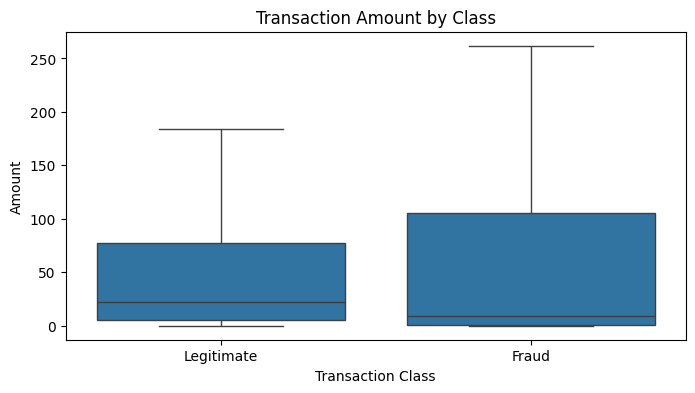

In [17]:
plt.figure(figsize=(8, 4))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount",
    showfliers=False
)

plt.xticks([0, 1], ["Legitimate", "Fraud"])
plt.title("Transaction Amount by Class")
plt.xlabel("Transaction Class")
plt.ylabel("Amount")
plt.show()

In [18]:
df.groupby("Class")["Amount"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


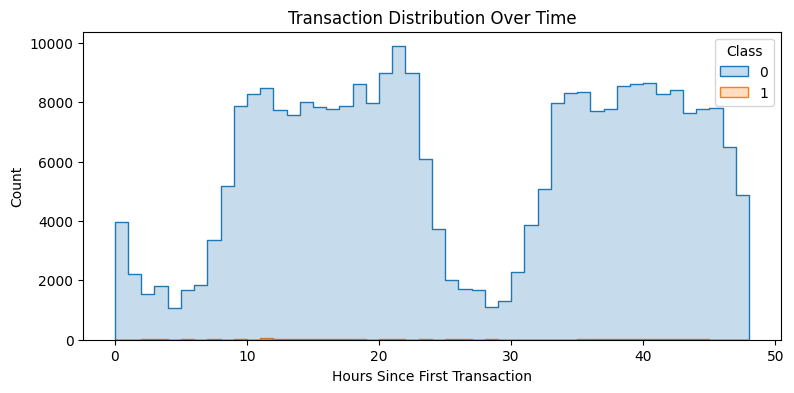

In [19]:
df["Hour"] = df["Time"] / 3600

plt.figure(figsize=(9, 4))

sns.histplot(
    data=df,
    x="Hour",
    hue="Class",
    bins=48,
    element="step",
    stat="count",
    common_norm=False
)

plt.title("Transaction Distribution Over Time")
plt.xlabel("Hours Since First Transaction")
plt.show()

In [20]:
original_df = df.drop(columns="Hour", errors="ignore")

print("Missing values:", original_df.isnull().sum().sum())
print("Duplicate rows:", original_df.duplicated().sum())

print("\nDuplicates by class:")
print(
    original_df.loc[
        original_df.duplicated(keep=False), "Class"
    ].value_counts()
)

Missing values: 0
Duplicate rows: 1081

Duplicates by class:
Class
0    1822
1      32
Name: count, dtype: int64


In [21]:
print("Split method: Chronological 60/20/20")
print("Features:", X_train.columns.tolist())

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        name,
        "Rows:", len(data),
        "Frauds:", int(data["Class"].sum()),
        "Fraud rate:", round(data["Class"].mean() * 100, 4), "%"
    )

Split method: Chronological 60/20/20
Features: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']
Train Rows: 170888 Frauds: 360 Fraud rate: 0.2107 %
Validation Rows: 56957 Frauds: 57 Fraud rate: 0.1001 %
Test Rows: 56962 Frauds: 75 Fraud rate: 0.1317 %
